In [1]:
import os
os.environ["KMP_WARNINGS"] = "0"
os.environ["OMP_NUM_THREADS"] = "1"

import glob
import json
import datetime

import warnings
warnings.filterwarnings("ignore", message="The specified chunks separate the stored chunks")

import zlib
import numpy as np
import pandas as pd
import xarray as xr
import cf_xarray
import intake_esm
import regionmask
import itertools

from shapely.geometry import box, MultiPolygon
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import confusion_matrix
from joblib import Parallel, delayed

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
from IPython.display import Markdown, display

In [2]:
def stable_seed(name):
    """Deterministic seed from a string"""
    return zlib.crc32(name.encode())

In [3]:
BASE = "/Users/charan/Desktop/SAI Summer (Updated)"

STRATEGIES = {
    "0N": "0N-LOWER-0.5",
    "15N_15S": "15N_15S-LOWER-0.5",
    "30N_30S": "30N_30S-LOWER-0.5",
    "60N_60S": "60N_60S-LOWER-0.5",
    "MULTI": "LOWER-0.5",
}

MULTI_TARGET_FOLDERS = {
    "0.5": "LOWER-0.5",
    "1.0": "LOWER-1.0",
    "gauss_default": "GAUSS-DEFAULT",
}

ARISE_BASE = "/Users/charan/Desktop/ARISE"
ARISE_FOLDERS = {"arise_1.5": "DEFAULT"}
ARISE_MEMBERS = [f"{i:03d}" for i in range(1, 11)]

STRATEGY_LABELS = {"0N": 0, "15N_15S": 1, "30N_30S": 2, "60N_60S": 3, "MULTI": 4}

_FOLDER_TO_STRATEGY = {v: k for k, v in STRATEGIES.items()}

MEMBERS = ["001", "002", "003"]
MIN_MONTHS_PER_YEAR = 12
YEARS = list(range(2035, 2070))

REGIONS = {
    # Zhang et al. (2024), Earth Syst. Dynam. 15, 191-213
    "tropical_mean":  dict(lat=(-20, 20), lon=(0, 360)),
    "amazon_basin":   dict(lat=(-15, 5),  lon=(282, 310)),   # 78W-50W
    "congo_basin":    dict(lat=(-10, 8),  lon=(12, 31)),
    "nino34":         dict(lat=(-5, 5),   lon=(190, 240)),   # 170W-120W
    "atlantic_mdr":   dict(lat=(5, 20),   lon=(275, 345)),   # 85W-15W
    # Bednarz et al. (2023), ACP 23, 13665-13684
    "natl_midlat":    dict(lat=(30, 60),  lon=(280, 360)),
    "polar_cap":      dict(lat=(70, 90),  lon=(0, 360)),
    "aleutian_low":   dict(lat=(30, 70),  lon=(140, 240)),
    # Narenpitak et al. (2024), Sci. Rep. 14, 22713
    "se_asia_monsoon": dict(lat=(0, 30), lon=(90, 110)),
}

# used for ICEFRAC only
SEAICE_REGIONS = {
    "arctic":         dict(lat=(65, 90),  lon=(0, 360)),
    "antarctic":      dict(lat=(-90, -65), lon=(0, 360)),
}

VARS = ["TREFHT", "PRECT", "ICEFRAC"]
OUTDIR = "outputs"
os.makedirs(OUTDIR, exist_ok=True)

In [4]:
SEAICE_MONTHS = {"arctic": 9, "antarctic": 3}

VAR_REGIONS = {"TREFHT": list(REGIONS), "PRECT": list(REGIONS), "ICEFRAC": list(SEAICE_MONTHS)}

def var_feats(var):
    """Regional feature names for one variable"""
    return [f"{var}_{r}" for r in VAR_REGIONS[var]]

In [5]:
CATALOG_DIR = "catalog"
CATALOG_CSV = os.path.join(CATALOG_DIR, "gauss_catalog.csv")
CATALOG_JSON = os.path.join(CATALOG_DIR, "gauss_catalog.json")

VAR_COMPONENT = {"TREFHT": "atm", "PRECT": "atm", "ICEFRAC": "atm"}

_CATALOG = None  #see build_catalog()

In [6]:
def build_catalog(force=False):
    """
    Scan BASE for the GAUSS NetCDF files and build a local intake-esm
    ESM-collection catalog (one row per strategy x member x variable).
    """
    global _CATALOG
    if _CATALOG is not None and not force:
        return _CATALOG

    if force or not (os.path.exists(CATALOG_CSV) and os.path.exists(CATALOG_JSON)):
        os.makedirs(CATALOG_DIR, exist_ok=True)
        rows = []
        for strat, folder in STRATEGIES.items():
            for mem in MEMBERS:
                d = os.path.join(BASE, f"{folder}.{mem}")
                for var, component in VAR_COMPONENT.items():
                    search_var = var
                    hits = glob.glob(os.path.join(d, f"*{search_var}*.nc"))
                    assert len(hits) == 1, f"expected exactly 1 file, got {hits} in {d}"
                    rows.append({"strategy": strat, "member": mem, "variable": var,
                                 "component": component, "path": hits[0]})
        pd.DataFrame(rows).to_csv(CATALOG_CSV, index=False)

        esmcat_spec = {
            "esmcat_version": "0.1.0",
            "id": "gauss-sai-catalog",
            "description": "Local file catalog for GAUSS SAI strategy-classification "
                            "NetCDF files (TREFHT/PRECT/ICEFRAC).",
            "catalog_file": os.path.abspath(CATALOG_CSV),
            "attributes": [
                {"column_name": "strategy", "vocabulary": ""},
                {"column_name": "member", "vocabulary": ""},
                {"column_name": "variable", "vocabulary": ""},
                {"column_name": "component", "vocabulary": ""},
            ],
            "assets": {"column_name": "path", "format": "netcdf"},
            "aggregation_control": {
                "variable_column_name": "variable",
                "groupby_attrs": ["strategy", "member", "component"],
                "aggregations": [],
            },
        }
        with open(CATALOG_JSON, "w") as f:
            json.dump(esmcat_spec, f, indent=2)

    _CATALOG = intake_esm.esm_datastore(CATALOG_JSON)
    return _CATALOG

In [7]:
def find_file(strategy_folder, member, var_tag):
    """Look up NetCDF file path via the intake-esm catalog"""
    strat = _FOLDER_TO_STRATEGY[strategy_folder]
    cat = build_catalog()
    sub = cat.search(strategy=strat, member=member, variable=var_tag)
    hits = sub.df["path"].tolist()
    assert len(hits) == 1, f"expected exactly 1 catalog hit, got {hits} for {strat}.{member}.{var_tag}"
    return hits[0]
    
def find_multi_target_file(target_folder, member, var_tag, base=BASE):
    """Look up NetCDF file for a MULTI run outside the intake-esm STRATEGIES catalog"""
    d = os.path.join(base, f"{target_folder}.{member}")
    hits = glob.glob(os.path.join(d, f"*{var_tag}*.nc"))
    assert len(hits) == 1, f"expected exactly 1 file, got {hits} in {d}"
    return hits[0]

In [8]:
START_YM = (2035, 1)
END_YM = (2069, 12)
EXPECTED_N_TIME = 420  # (2069 - 2035) * 12 + 12


def check_icefrac_file(fpath, var="ICEFRAC"):
    name = os.path.basename(fpath)
    problems, info = [], {"file": name}

    sy, sm = START_YM
    ey, em = END_YM
    exp_months = EXPECTED_N_TIME
    info["advertised"] = f"{sy:04d}{sm:02d}-{ey:04d}{em:02d}  (expect {exp_months} months)"

    ds = xr.open_dataset(fpath)                                        # CF-decoded
    rawds = xr.open_dataset(fpath, mask_and_scale=False, decode_times=False)
    try:
        if var not in ds.variables:
            problems.append(f"{var} not in file")
            print("FAIL " + name, "->", problems)
            return False, {**info, "problems": problems}
        da = ds[var]

        nt = ds.sizes["time"]
        # check if all 420 months are present
        info["n_time"] = nt
        if nt != exp_months:
            problems.append(f"time length {nt} != expected {exp_months}")

        tv = ds["time"].values
        yr = np.asarray(ds["time"].dt.year.values, dtype="int64")
        mo = np.asarray(ds["time"].dt.month.values, dtype="int64")
        ym = yr * 12 + (mo - 1)
        info["data_range"] = f"{yr[0]:04d}-{mo[0]:02d} .. {yr[-1]:04d}-{mo[-1]:02d}"
        
        if any(tv[i] >= tv[i + 1] for i in range(len(tv) - 1)):
            problems.append("time not strictly increasing (out-of-order or duplicate stamps)")
        if len(np.unique(ym)) != len(ym):
            problems.append("duplicate year-month(s) on the time axis")
        gaps = np.where(np.diff(ym) != 1)[0]
        if len(gaps):
            # verify every month index is 1 higher than the previous month's index
            eg = [f"{yr[i]:04d}-{mo[i]:02d}->{yr[i+1]:04d}-{mo[i+1]:02d}" for i in gaps[:5]]
            problems.append(f"{len(gaps)} non-monthly step(s): {eg}")

        bname = next((b for b in ("time_bnds", "time_bounds") if b in ds.variables), None)
        if bname is not None:
            flat = list(np.asarray(ds[bname].values).ravel())
            b0, b1 = min(flat), max(flat)
            info["bounds_range"] = f"{b0.year:04d}-{b0.month:02d} .. {b1.year:04d}-{b1.month:02d}"
            nxt = (ey + 1, 1) if em == 12 else (ey, em + 1)      # bounds end = start of next month
            if (b0.year, b0.month) != (sy, sm):
                problems.append(f"bounds start {b0.year}-{b0.month:02d} != expected {sy}-{sm:02d}")
            if (b1.year, b1.month) != nxt:
                problems.append(f"bounds end {b1.year}-{b1.month:02d} != expected {nxt[0]}-{nxt[1]:02d}")
        else:
            if (yr[0], mo[0]) != (sy, sm):
                problems.append(f"data start {yr[0]}-{mo[0]:02d} != expected {sy}-{sm:02d}")
            if (yr[-1], mo[-1]) != (ey, em):
                problems.append(f"data end {yr[-1]}-{mo[-1]:02d} != expected {ey}-{em:02d}")

        v = np.asarray(da.values, dtype="float64")
        spatial = tuple(range(1, v.ndim))
        finite = np.isfinite(v)
        # count NaNs and any infinite values
        info["dtype"] = str(da.dtype)
        info["n_nan"] = int((~finite).sum())
        info["n_inf"] = int(np.isinf(v).sum())
        if np.isinf(v).any():
            problems.append(f"{info['n_inf']} infinite value(s)")

        # calculate global minimum and maximum values
        if finite.any():
            vmin, vmax = float(np.nanmin(v)), float(np.nanmax(v))
        else:
            vmin = vmax = float("nan")
            problems.append("no finite values at all")
        info["min"], info["max"] = vmin, vmax

        # verify ICEFRAC value is between 0 and 1
        EPS = 1e-6
        n_neg = int(np.sum(finite & (v < -EPS)))
        n_gt1 = int(np.sum(finite & (v > 1 + EPS)))
        if n_neg:
            problems.append(f"{n_neg} negative value(s); min={vmin:.6g}")
        if n_gt1:
            problems.append(f"{n_gt1} value(s) > 1; max={vmax:.6g}")

        allnan_t = np.where((~finite).all(axis=spatial))[0]
        if len(allnan_t):
            problems.append(f"{len(allnan_t)} fully-NaN timestep(s); idx {list(allnan_t[:10])}")

        big = finite & (np.abs(v) > 1e10)
        info["n_abs_gt_1e10"] = int(big.sum())
        if big.any():
            problems.append(f"{int(big.sum())} value(s) |x|>1e10 (unmasked fill?); "
                            f"max|x|={np.abs(v[finite]).max():.3e}")
        # verify sentinel numbers like 1e20 are not present in the dataset
        for s in (1e20, -1e20, 9.96920996838687e36, 1e15, -9999.0, -999.0):
            c = int(np.sum(finite & np.isclose(v, s, rtol=0, atol=max(abs(s) * 1e-6, 1e-6))))
            if c:
                problems.append(f"{c} value(s) == sentinel {s:g} in decoded data")

        rv = rawds[var]
        fill = rv.attrs.get("_FillValue", rv.encoding.get("_FillValue"))
        # verify raw v. xarray decoded dataset
        miss = rv.attrs.get("missing_value")
        info["declared_FillValue"] = fill
        info["declared_missing_value"] = miss
        rvv = np.asarray(rv.values, dtype="float64")
        for lbl, fv in (("_FillValue", fill), ("missing_value", miss)):
            if fv is None:
                continue
            fv = float(np.asarray(fv).ravel()[0])
            tol = max(abs(fv) * 1e-6, 1e-6)
            n_raw = int(np.sum(np.isclose(rvv, fv, rtol=0, atol=tol)))
            n_kept = int(np.sum(finite & np.isclose(v, fv, rtol=0, atol=tol)))
            if n_raw and n_kept:
                problems.append(f"{lbl} {fv:g}: {n_kept}/{n_raw} not converted to NaN")
    finally:
        ds.close()
        rawds.close()

    ok = not problems
    print(("OK   " if ok else "FAIL ") + name)
    for k, val in info.items():
        if k != "file":
            print(f"       {k:22s}: {val}")
    for p in problems:
        print(f"       !! {p}")
    print()
    return ok, {**info, "problems": problems}

_files = sorted(glob.glob(os.path.join(BASE, f"{STRATEGIES['0N']}.*", "*ICEFRAC*.nc")))

_results = [check_icefrac_file(f) for f in _files]
print("SUMMARY:", {r[1]["file"][-30:]: ("OK" if r[0] else r[1]["problems"]) for r in _results})


# verify every file spans 2035-01 to 2069-12 (420 months)

EXPECTED_N_TIME = 420   # 35 years x 12

def check_uniform_time_axis():
    build_catalog(force=True)
    bad = []
    for strat, folder in STRATEGIES.items():
        for mem in MEMBERS:
            for var in ["TREFHT", "PRECT", "ICEFRAC"]:
                fp = find_file(folder, mem, var)
                with xr.open_dataset(fp) as ds:
                    nt = int(ds.sizes["time"])
                if nt != EXPECTED_N_TIME:
                    bad.append((strat, mem, var, nt))
                    print(f"  MISMATCH {strat}.{mem} {var}: n_time={nt} (expected {EXPECTED_N_TIME})")
    if bad:
        raise AssertionError(f"{len(bad)} file(s) have the wrong number of months")
    print(f"All {len(STRATEGIES) * len(MEMBERS) * 3} files have {EXPECTED_N_TIME} months.")

check_uniform_time_axis()

OK   b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.feedback_0N_1.0.001.cam.h0.ICEFRAC.203501-206912.nc
       advertised            : 203501-206912  (expect 420 months)
       n_time                : 420
       data_range            : 2035-02 .. 2070-01
       bounds_range          : 2035-01 .. 2070-01
       dtype                 : float32
       n_nan                 : 0
       n_inf                 : 0
       min                   : 0.0
       max                   : 0.9999979138374329
       n_abs_gt_1e10         : 0
       declared_FillValue    : -900.0
       declared_missing_value: None

OK   b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.feedback_0N_1.0.002.cam.h0.ICEFRAC.203501-206912.nc
       advertised            : 203501-206912  (expect 420 months)
       n_time                : 420
       data_range            : 2035-02 .. 2070-01
       bounds_range          : 2035-01 .. 2070-01
       dtype                 : float32
       n_nan                 : 0
    

In [9]:
# area weighted regional means

def _box_outline(lat_range, lon_range):
    """Shapely box (or MultiPolygon split at the 0/360 seam for wraparound regions."""
    lat0, lat1 = lat_range
    lo, hi = lon_range
    if lo <= hi:
        return box(lo, lat0, hi, lat1)
    return MultiPolygon([box(lo, lat0, 360, lat1), box(0, lat0, hi, lat1)])


def build_regions(region_defs):
    """Build a regionmask.Regions object from a {name: {lat:(lo,hi), lon:(lo,hi)}} dict."""
    names = list(region_defs.keys())
    outlines = [_box_outline(region_defs[n]["lat"], region_defs[n]["lon"]) for n in names]
    return regionmask.Regions(outlines, names=names, abbrevs=[n[:4] for n in names], name="SAI regions", overlap=True)

In [10]:
def cf_lat_cell_weights(lat_da):
    """
    cos(latitude) cell weights for a regular lat/lon grid
    """
    w = np.cos(np.deg2rad(lat_da.values))
    return xr.DataArray(w, dims="lat", coords={"lat": lat_da["lat"] if "lat" in lat_da.coords else lat_da})

In [11]:
def regional_means_latlon(annual, region_defs):
    """cos(latitude)-weighted regional means for a regular lat/lon
    grid"""
    regions = build_regions(region_defs)
    mask3d = regions.mask_3D(annual, wrap_lon=360, use_cf=False)
    weights = cf_lat_cell_weights(annual["lat"])
    out = {}
    for i, name in enumerate(regions.names):
        m = mask3d.sel(region=i)
        out[name] = annual.where(m).weighted(weights.fillna(0)).mean(dim=("lat", "lon"), skipna=True)
    return out

In [12]:
def _open_monthly(fpath, varname):
    """Open a monthly file with time stamps moved to the middle of each month"""
    ds = xr.open_dataset(fpath, chunks={"time": 60})
    if "time_bnds" in ds.variables:
        ds = ds.assign_coords(time=ds["time_bnds"].mean(ds["time_bnds"].dims[-1]))
    else:
        print(f"  [NO time_bnds] {os.path.basename(fpath)} ({varname}) "
              f"-- shifting time back 15 days")
        ds = ds.assign_coords(time=ds.get_index("time") - datetime.timedelta(days=15))
    return ds, ds[varname]

def annual_mean_region_series(fpath, varname, region_defs):
    ds, da = _open_monthly(fpath, varname)
    annual = da.groupby("time.year").mean("time", skipna=True)
    n_months = da["time"].groupby("time.year").count()
    annual = annual.where(n_months >= MIN_MONTHS_PER_YEAR)
    means = regional_means_latlon(annual, region_defs)
    out = {}
    for rname, rmean in means.items():
        rmean = rmean.compute()
        out[rname] = pd.Series(rmean.values, index=rmean["year"].values).reindex(YEARS)
    ds.close()
    return out

def seaice_month_region_series(fpath, varname="ICEFRAC", seaice_months=SEAICE_MONTHS):
    """
    Area-weighted sea-ice fraction in each polar region for that hemisphere's
    minimum month only (September Arctic, March Antarctic), one value per year
    """
    ds, da = _open_monthly(fpath, varname)
    out = {}
    for rname, month in seaice_months.items():
        da_m = da.isel(time=np.flatnonzero(da["time"].dt.month.values == month))
        monthly = da_m.groupby("time.year").mean("time", skipna=True)
        rmean = regional_means_latlon(monthly, {rname: SEAICE_REGIONS[rname]})[rname].compute()
        out[rname] = pd.Series(rmean.values, index=rmean["year"].values).reindex(YEARS)
    ds.close()
    return out

In [13]:
GLOBAL_REGION = {"global": dict(lat=(-90, 90), lon=(0, 360))}

GLOBAL_VARS = ["TREFHT", "PRECT"]
GLOBAL_FEATS = [f"{v}_global" for v in GLOBAL_VARS] + var_feats("ICEFRAC")

In [14]:
def build_global_mean_matrix():
    """
    Global area-weighted annual means for TREFHT/PRECT. Sea ice is taken from
    the polar September/March features using the regional mean function instead.
    """
    rows = []
    for strat, folder in STRATEGIES.items():
        for mem in MEMBERS:
            d = {var: annual_mean_region_series(find_file(folder, mem, var), var, GLOBAL_REGION)
                 for var in GLOBAL_VARS}
            for year in YEARS:
                row = {"strategy": strat, "member": mem, "year": year}
                for var in GLOBAL_VARS:
                    row[f"{var}_global"] = d[var]["global"].loc[year]
                rows.append(row)
            print(f"  extracted global means: {strat}.{mem}")
    return pd.DataFrame(rows)

In [15]:
# find files and build features

def build_feature_matrix():
    rows = []
    for strat, folder in STRATEGIES.items():
        for mem in MEMBERS:
            f_t = find_file(folder, mem, "TREFHT")
            f_p = find_file(folder, mem, "PRECT")
            f_i = find_file(folder, mem, "ICEFRAC")
            d = {
                "TREFHT": annual_mean_region_series(f_t, "TREFHT", REGIONS),
                "PRECT": annual_mean_region_series(f_p, "PRECT", REGIONS),
                "ICEFRAC": seaice_month_region_series(f_i, "ICEFRAC"),
            }
            for year in YEARS:
                row = {"strategy": strat, "label": STRATEGY_LABELS[strat], "member": mem, "year": year}
                for var in VARS:
                    for rname in d[var]:
                        row[f"{var}_{rname}"] = d[var][rname].loc[year]
                rows.append(row)
            print(f"  extracted {strat}.{mem}")
    return pd.DataFrame(rows)

def build_multi_target_feature_matrix(target_folders, base=BASE, members=MEMBERS):
    """
    Regional and global features for MULTI runs at other temperature targets or from other datasets
    """
    region_defs = {**REGIONS, **GLOBAL_REGION}
    rows = []
    for target_id, folder in target_folders.items():
        for mem in members:
            d = {}
            for var in VARS:
                fpath = find_multi_target_file(folder, mem, var, base=base)
                d[var] = (seaice_month_region_series(fpath, var) if var == "ICEFRAC"
                          else annual_mean_region_series(fpath, var, region_defs))
            for year in YEARS:
                row = {"strategy": "MULTI", "label": STRATEGY_LABELS["MULTI"],
                       "member": mem, "year": year, "target": target_id}
                for var in VARS:
                    for rname in d[var]:
                        row[f"{var}_{rname}"] = d[var][rname].loc[year]
                rows.append(row)
            print(f"  extracted MULTI target={target_id} ({folder}).{mem}")
    return pd.DataFrame(rows)

In [16]:
# leave one-member-out logistic regression

In [17]:
def _make_pipeline(C, random_state):
    """StandardScaler + multinomial LogisticRegression"""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=C, max_iter=2000, random_state=random_state)),
    ])

def lomo_pooled_train_peryear_eval(df, feature_cols, years=YEARS, members=MEMBERS, C=0.1, random_state=0):
    """
    Rotate through 3 folds (hold out one member at a time) using
    sklearn.model_selection.LeaveOneGroupOut (groups = ensemble member).
    """
    sub = df.dropna(subset=feature_cols + ["label"]).copy().reset_index(drop=True)
    X = sub[feature_cols].values
    y = sub["label"].values
    groups = sub["member"].values

    logo = LeaveOneGroupOut()
    acc_per_fold = {}
    for train_idx, test_idx in logo.split(X, y, groups):
        held_out = groups[test_idx][0]
        pipe = _make_pipeline(C, random_state)
        pipe.fit(X[train_idx], y[train_idx])

        test = sub.iloc[test_idx]
        yearly_acc = []
        for year in years:
            tst_y = test[test["year"] == year]
            if len(tst_y) == 0:
                print(f"Notice: No data for member {held_out} in year {year}. Inserting NaN.")
                yearly_acc.append(np.nan)
                continue
            yearly_acc.append(pipe.score(tst_y[feature_cols].values, tst_y["label"].values))
        acc_per_fold[held_out] = yearly_acc
        
    fold_arrs = np.array([acc_per_fold[m] for m in acc_per_fold])
    curve = pd.DataFrame(
        {"year": years, "mean_acc": np.nanmean(fold_arrs, axis=0), "std_acc": np.nanstd(fold_arrs, axis=0)}
    )
    curve["smooth_acc"] = curve["mean_acc"].rolling(5, center=True, min_periods=1).mean()
    return curve, fold_arrs

def lomo_transfer_eval(df, df_multi_test, feature_cols, years=YEARS, members=MEMBERS, C=0.1,
                       random_state=0, unpaired_targets=()):
    """
    Cross-target / cross-dataset generalization. Each leave-one-member-out fold is
    trained on the original-target data and scored on MULTI runs in df_multi_test.
    """
    train_all = df.dropna(subset=feature_cols + ["label"])
    test_all = df_multi_test.dropna(subset=feature_cols + ["label"])
    targets = list(dict.fromkeys(test_all["target"]))
    scores = {t: [] for t in targets}
    pred_parts = []
    for held_out in members:
        train = train_all[train_all["member"] != held_out]
        pipe = _make_pipeline(C, random_state)
        pipe.fit(train[feature_cols].values, train["label"].values)
        for t in targets:
            test = test_all[test_all["target"] == t]
            if t not in unpaired_targets:
                test = test[test["member"] == held_out]
            proba = pipe.predict_proba(test[feature_cols].values)
            col = np.searchsorted(pipe.classes_, test["label"].values)
            test = test.assign(pred=pipe.classes_[proba.argmax(axis=1)],
                               p_true=proba[np.arange(len(test)), col], fold=held_out)
            scores[t].append(test.groupby("year")["p_true"].mean().reindex(years).values)
            pred_parts.append(test[["target", "member", "fold", "year", "label", "pred", "p_true"]])

    curves = {}
    for t in targets:
        fold_arrs = np.array(scores[t], dtype=float)
        curve = pd.DataFrame({"year": years, "mean_acc": np.nanmean(fold_arrs, axis=0),
                              "std_acc": np.nanstd(fold_arrs, axis=0)})
        curve["smooth_acc"] = curve["mean_acc"].rolling(5, center=True, min_periods=1).mean()
        curves[t] = curve
    return curves, pd.concat(pred_parts, ignore_index=True)

In [18]:
def lomo_confusion(df, feature_cols, year_range, members=MEMBERS, C=0.1, random_state=0):
    sub = df.dropna(subset=feature_cols + ["label"]).copy()
    sub = sub[(sub["year"] >= year_range[0]) & (sub["year"] <= year_range[1])].reset_index(drop=True)
    X = sub[feature_cols].values
    y = sub["label"].values
    groups = sub["member"].values

    logo = LeaveOneGroupOut()
    all_true, all_pred = [], []
    for train_idx, test_idx in logo.split(X, y, groups):
        pipe = _make_pipeline(C, random_state)
        pipe.fit(X[train_idx], y[train_idx])
        pred = pipe.predict(X[test_idx])
        all_true.extend(y[test_idx])
        all_pred.extend(pred)
    return confusion_matrix(all_true, all_pred, labels=list(STRATEGY_LABELS.values())), np.array(all_true), np.array(all_pred)

In [19]:
def emergence_year(curve, threshold=0.5, col="smooth_acc"):
    above = curve[col].values > threshold
    if not above.any():
        return None
    return curve["year"].values[np.argmax(above)]

In [20]:
# permutation-based emergence test

In [21]:
def _one_null_permutation(df, feature_cols, years, members, C, seed):
    """
    Within each member, draw a random bijection on the strategy labels and apply it to the trajectories.
    Resulting in each strategy's full time series keeping its years together and taking another strategy's label.
    Evaluate the LOMO accuracy curve.
    """
    rng = np.random.default_rng(seed)
    dfp = df.copy()
    labels = np.sort(dfp["label"].unique())
    label_dtype = dfp["label"].dtype
    for mem in members:
        idx = dfp.index[dfp["member"] == mem]
        mapping = dict(zip(labels, rng.permutation(labels)))
        dfp.loc[idx, "label"] = dfp.loc[idx, "label"].map(mapping).astype(label_dtype)
    curve, _ = lomo_pooled_train_peryear_eval(dfp, feature_cols, years=years, members=members, C=C)
    return curve["mean_acc"].values

In [22]:
def generate_null_curves(df, feature_cols, n_perm=10000, members=MEMBERS, years=YEARS,
                          C=0.1, seed=0, n_jobs=-1, verbose=0):
    """
    Apply one_null_permutation n_perm times
    """
    sub = df.dropna(subset=feature_cols + ["label"]).copy()
    child_seeds = np.random.SeedSequence(seed).spawn(n_perm)

    results = Parallel(n_jobs=n_jobs, backend="loky", verbose=verbose)(
        delayed(_one_null_permutation)(sub, feature_cols, years, members, C, child_seeds[p])
        for p in range(n_perm)
    )
    return np.array(results)

def _one_null_permutation_transfer(df, df_multi_test, feature_cols, years, members, C, seed,
                                   unpaired_targets=()):
    """
    Same restricted permutation as _one_null_permutation. One random bijection of the
    strategy labels per member, applied to that member's training trajectories and
    to its own MULTI runs at the other targets.
    """
    rng = np.random.default_rng(seed)
    labels = np.sort(df["label"].unique())
    label_dtype = df["label"].dtype
    dfp, testp = df.copy(), df_multi_test.copy()
    paired = ~testp["target"].isin(unpaired_targets)
    for mem in members:
        mapping = dict(zip(labels, rng.permutation(labels)))
        idx = dfp.index[dfp["member"] == mem]
        dfp.loc[idx, "label"] = dfp.loc[idx, "label"].map(mapping).astype(label_dtype)
        idx = testp.index[paired & (testp["member"] == mem)]
        testp.loc[idx, "label"] = testp.loc[idx, "label"].map(mapping).astype(label_dtype)
    curves, _ = lomo_transfer_eval(dfp, testp, feature_cols, years=years, members=members, C=C,
                                   unpaired_targets=unpaired_targets)
    return np.array([curves[t]["mean_acc"].values for t in curves])


def generate_null_curves_transfer(df, df_multi_test, feature_cols, n_perm=10000, members=MEMBERS,
                                   years=YEARS, C=0.1, seed=0, n_jobs=-1, verbose=0,
                                   unpaired_targets=()):
    """Apply _one_null_permutation_transfer n_perm times. Returns {target: (n_perm, n_years) array}"""
    sub = df.dropna(subset=feature_cols + ["label"]).copy()
    test = df_multi_test.dropna(subset=feature_cols + ["label"]).copy()
    targets = list(dict.fromkeys(test["target"]))
    child_seeds = np.random.SeedSequence(seed).spawn(n_perm)
    results = np.array(Parallel(n_jobs=n_jobs, backend="loky", verbose=verbose)(
        delayed(_one_null_permutation_transfer)(sub, test, feature_cols, years, members, C,
                                                child_seeds[p], unpaired_targets)
        for p in range(n_perm)
    ))
    return {t: results[:, i, :] for i, t in enumerate(targets)}

In [23]:
def max_stat_band(null_curves, alpha=0.05):
    """FWER-controlled threshold"""
    return np.percentile(np.nanmax(null_curves, axis=1), 100 * (1 - alpha))

def null_run_length_distribution(null_curves, threshold):
    """Longest run of consecutive years exceeding `threshold`, per null permutation draw"""
    n_perm = null_curves.shape[0]
    longest_runs = np.zeros(n_perm, dtype=int)
    for p in range(n_perm):
        above = null_curves[p, :] > threshold
        run = best = 0
        for a in above:
            run = run + 1 if a else 0
            best = max(best, run)
        longest_runs[p] = best
    return longest_runs

In [24]:
def emergence_year_fwer(real_curve_vals, null_curves, years=YEARS, alpha=0.20, k_consecutive=None, run_alpha=0.05):
    """
    Emergence-year test using a family-wise (max-statistic) permutation band, with
    an automatically calibrated consecutive-year run-length requirement controlling
    P(false emergence) <= run_alpha
    """
    thresh = max_stat_band(null_curves, alpha=alpha)
    above = real_curve_vals > thresh
    runs_null = null_run_length_distribution(null_curves, thresh)

    if k_consecutive is None:
        k_consecutive = len(years)
        for k in range(1, len(years) + 1):
            if np.mean(runs_null >= k) <= run_alpha:
                k_consecutive = k
                break
    p_run_at_k = np.mean(runs_null >= k_consecutive)

    ey = None
    for i in range(len(above) - k_consecutive + 1):
        if above[i:i + k_consecutive].all():
            ey = years[i]
            break

    return {"fwer_threshold": thresh, "k_consecutive_required": k_consecutive,
            "p_null_run_at_k": p_run_at_k, "emergence_year": ey}

def run_length_calibration(null_curves, alpha=0.20, max_k=8):
    """P(a null curve stays above the FWER threshold for >= k consecutive years), for k = 1..max_k"""
    thresh = max_stat_band(null_curves, alpha=alpha)
    runs = null_run_length_distribution(null_curves, thresh)
    return pd.Series({k: np.mean(runs >= k) for k in range(1, max_k + 1)}, name="p_null_run_ge_k")

In [25]:
def global_fwer_pvalue(real_curve_vals, null_curves):
    """Family-wise p-value for the real curve's peak accuracy against the null max-statistic distribution"""
    per_draw_max = np.nanmax(null_curves, axis=1)
    real_max = np.nanmax(real_curve_vals)
    return (np.sum(per_draw_max >= real_max) + 1) / (len(per_draw_max) + 1)

# global feature combinations to verify if all 3 features are needed

def run_feature_combinations(df, base_features, n_perm=10000, label=None, outdir=OUTDIR):
    """
    Test every non-empty subset of `base_features through the full LOMO + FWER permutation
    pipeline, at full n_perm directly
    """
    combos = list(itertools.chain.from_iterable(
        itertools.combinations(base_features, r)
        for r in range(1, len(base_features) + 1)
    ))
    print(f"Testing {len(combos)} feature combinations (n_perm={n_perm} each)...")
    rows, curves = [], {}
    for combo in combos:
        feats = list(combo)
        name = "+".join(f.replace("_global", "").replace("_", "") for f in feats)
        curve, _ = lomo_pooled_train_peryear_eval(df, feats)
        curves[name] = curve
        null_curves = generate_null_curves(df, feats, n_perm=n_perm,
                                            seed=stable_seed(f"{label}:{name}"))
        res = emergence_year_fwer(curve["mean_acc"].values, null_curves)
        pval = global_fwer_pvalue(curve["mean_acc"].values, null_curves)
        rows.append({
            "n_features": len(feats),
            "combination": name,
            "features": feats,
            "naive_emergence_year": emergence_year(curve),
            "fwer_emergence_year": res["emergence_year"],
            "k_consecutive_required": res["k_consecutive_required"],
            "fwer_threshold": res["fwer_threshold"],
            "peak_acc": np.nanmax(curve["mean_acc"].values),
            "final_smooth_acc": curve["smooth_acc"].iloc[-1],
            "global_fwer_pvalue_of_peak": pval,
            "n_perm": n_perm,
        })
        print(f"  {name:16s}: FWER emergence year={res['emergence_year']}, "
              f"peak_acc={np.nanmax(curve['mean_acc'].values):.3f}, "
              f"peak p-value={pval:.5f}")
    result_df = pd.DataFrame(rows).sort_values(
        ["n_features", "global_fwer_pvalue_of_peak"]).reset_index(drop=True)
    fname = f"combination_test_{label}.csv" if label else "combination_test.csv"
    result_df.to_csv(os.path.join(outdir, fname), index=False)
    print(f"\nSaved to {outdir}/{fname}\n")
    print(result_df.drop(columns="features").to_string(index=False))
    return result_df, curves

In [26]:
# statistical tests: benjamini_hochberg and holm_bonferroni

def benjamini_hochberg(pvals, alpha=0.05):
    """
    FDR control (expected proportion of false discoveries among rejections).
    """
    p = np.asarray(pvals, float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    passed = ranked <= alpha * (np.arange(1, n + 1) / n)
    rej = np.zeros(n, bool)
    if passed.any():
        rej[order[:np.max(np.where(passed)[0]) + 1]] = True
    adj = np.clip(np.minimum.accumulate((ranked * n / np.arange(1, n + 1))[::-1])[::-1], 0, 1)
    out = np.empty(n)
    out[order] = adj
    return rej, out


def holm_bonferroni(pvals, alpha=0.05):
    """
    FWER control (probability of any false discovery), stricter than BH.
    """
    p = np.asarray(pvals, float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    thresholds = alpha / (n - np.arange(n))
    rej = np.zeros(n, bool)
    for i in range(n):
        if ranked[i] <= thresholds[i]:
            rej[order[i]] = True
        else:
            break
    return rej

In [27]:
n_classes = len(STRATEGIES)
chance = 1.0 / n_classes
print(f"Classifying {n_classes} strategies, chance level = {chance:.3f}")

print("Building intake-esm file catalog...")
build_catalog(force=True)

Classifying 5 strategies, chance level = 0.200
Building intake-esm file catalog...


,unique
strategy,5
member,3
variable,3
component,1
path,45
derived_variable,0


In [28]:
print("Extracting regional annual means from NetCDF files...")
df = build_feature_matrix()
df.to_csv(os.path.join(OUTDIR, "feature_matrix.csv"), index=False)
print(f"Feature matrix: {df.shape}, saved to {OUTDIR}/feature_matrix.csv")

region_names = list(REGIONS.keys())
headline_results = []

# Per-variable (all regions) models
curves_by_variable = {}
for var in VARS:
    feats = var_feats(var)
    curve, _ = lomo_pooled_train_peryear_eval(df, feats)
    curves_by_variable[var] = curve
    curve.to_csv(os.path.join(OUTDIR, f"accuracy_curve_{var}.csv"), index=False)

    null_curves = generate_null_curves(df, feats, n_perm=10000, seed=stable_seed(var))
    res = emergence_year_fwer(curve["mean_acc"].values, null_curves)
    pval = global_fwer_pvalue(curve["mean_acc"].values, null_curves)
    headline_results.append({"test": f"{var} (regional)", "fwer_emergence_year": res["emergence_year"],
                             "k_consecutive_required": res["k_consecutive_required"], "p_value": pval})
    print(f"{var}: naive emergence year = {emergence_year(curve)}, "
          f"FWER emergence year = {res['emergence_year']}, "
          f"final smoothed acc = {curve['smooth_acc'].iloc[-1]:.3f}, "
          f"peak p-value = {pval:.5f}")

# Combined all-variable, all-region model
feats_all = [f for v in VARS for f in var_feats(v)]

_cov = df.groupby("year")[feats_all].apply(lambda g: g.notna().all(axis=1).sum())
print(f"complete rows per year (of {df['member'].nunique() * len(STRATEGIES)}): "
      f"{_cov.min()} min, {_cov.max()} max")
if (_cov < _cov.max()).any():
    print("  years with incomplete coverage:", list(_cov[_cov < _cov.max()].index))

curve_all, _ = lomo_pooled_train_peryear_eval(df, feats_all)
curve_all.to_csv(os.path.join(OUTDIR, "accuracy_curve_all_variables.csv"), index=False)

null_curves_all = generate_null_curves(df, feats_all, n_perm=10000, seed=stable_seed("ALL"))
res_all = emergence_year_fwer(curve_all["mean_acc"].values, null_curves_all)
pval_all = global_fwer_pvalue(curve_all["mean_acc"].values, null_curves_all)
headline_results.append({"test": "ALL (regional)", "fwer_emergence_year": res_all["emergence_year"],
                         "k_consecutive_required": res_all["k_consecutive_required"], "p_value": pval_all})
print(f"ALL variables+regions: naive emergence year = {emergence_year(curve_all)}, "
      f"FWER emergence year = {res_all['emergence_year']}, "
      f"final smoothed acc = {curve_all['smooth_acc'].iloc[-1]:.3f}, "
      f"peak p-value = {pval_all:.5f}")

# Per single region+variable models
rows = []
single_curves = {}
for var in VARS:
    for r in VAR_REGIONS[var]:
        feat = f"{var}_{r}"
        c, _ = lomo_pooled_train_peryear_eval(df, [feat])
        single_curves[feat] = c
        null_curves_r = generate_null_curves(df, [feat], n_perm=10000, seed=stable_seed(feat))
        res_r = emergence_year_fwer(c["mean_acc"].values, null_curves_r)
        pval_r = global_fwer_pvalue(c["mean_acc"].values, null_curves_r)
        rows.append({
            "variable": var, "region": r,
            "naive_emergence_year": emergence_year(c),
            "fwer_emergence_year": res_r["emergence_year"],
            "k_consecutive_required": res_r["k_consecutive_required"],
            "fwer_threshold": res_r["fwer_threshold"],
            "final_smooth_acc": c["smooth_acc"].iloc[-1],
            "max_smooth_acc": c["smooth_acc"].max(),
            "peak_acc": np.nanmax(c["mean_acc"].values),
            "global_fwer_pvalue_of_peak": pval_r,
        })
        print(f"  {feat:24s}: FWER emergence year={res_r['emergence_year']}, "
              f"peak p-value={pval_r:.5f}")

emergence_df = pd.DataFrame(rows)

# FDR control across all region-variable pairs
rej, padj = benjamini_hochberg(emergence_df["global_fwer_pvalue_of_peak"].values, alpha=0.05)
emergence_df["p_fdr_bh"] = padj
emergence_df["significant_fdr05"] = rej
emergence_df = emergence_df.sort_values("global_fwer_pvalue_of_peak").reset_index(drop=True)

n_sig = int(rej.sum())
print(f"\n{n_sig}/{len(emergence_df)} region-variable pairs significant at FDR 0.05")
if n_sig > 0:
    print(emergence_df.loc[emergence_df["significant_fdr05"],
                            ["variable", "region", "fwer_emergence_year",
                             "peak_acc", "global_fwer_pvalue_of_peak", "p_fdr_bh"]]
          .to_string(index=False))

emergence_df.to_csv(os.path.join(OUTDIR, "single_region_variable_emergence.csv"), index=False)

Extracting regional annual means from NetCDF files...
  extracted 0N.001
  extracted 0N.002
  extracted 0N.003
  extracted 15N_15S.001
  extracted 15N_15S.002
  extracted 15N_15S.003
  extracted 30N_30S.001
  extracted 30N_30S.002
  extracted 30N_30S.003
  extracted 60N_60S.001
  extracted 60N_60S.002
  extracted 60N_60S.003
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-0.5.001.cam.h0.TREFHT.203501-206912.nc (TREFHT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-0.5.001.cam.h0.PRECT.203501-206912.nc (PRECT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-0.5.001.cam.h0.ICEFRAC.203501-206912.nc (ICEFRAC) -- shifting time back 15 days
  extracted MULTI.001
  extracted MULTI.002
  extracted MULTI.003
Feature matrix: (525, 24), saved to outputs/feature_matrix.csv
TREFHT: naive emergence year

In [29]:
# Confusion matrices, early vs late deployment period

cm_early, _, _ = lomo_confusion(df, feats_all, (YEARS[0], YEARS[0] + 9))
cm_late, _, _ = lomo_confusion(df, feats_all, (YEARS[-10], YEARS[-1]))
pd.DataFrame(cm_early, index=list(STRATEGIES), columns=list(STRATEGIES)).to_csv(
    os.path.join(OUTDIR, "confusion_matrix_early.csv"))
pd.DataFrame(cm_late, index=list(STRATEGIES), columns=list(STRATEGIES)).to_csv(
    os.path.join(OUTDIR, "confusion_matrix_late.csv"))

In [30]:
# Global-mean vs regional-mean comparison
print("\nExtracting global-mean feature matrix...")
global_df = build_global_mean_matrix()
df_full = df.merge(global_df, on=["strategy", "member", "year"], how="left")
df_full.to_csv(os.path.join(OUTDIR, "feature_matrix_with_global.csv"), index=False)

feats_global = GLOBAL_FEATS
# the polar sea-ice features are in both sets, so drop the duplicates
feats_global_plus_regional = list(dict.fromkeys(feats_global + feats_all))

curve_global, _ = lomo_pooled_train_peryear_eval(df_full, feats_global)
curve_global_plus_regional, _ = lomo_pooled_train_peryear_eval(df_full, feats_global_plus_regional)
curve_global.to_csv(os.path.join(OUTDIR, "accuracy_curve_global_only.csv"), index=False)
curve_global_plus_regional.to_csv(os.path.join(OUTDIR, "accuracy_curve_global_plus_regional.csv"), index=False)

for name, feats, curve in [("global_only", feats_global, curve_global),
                           ("global_plus_regional", feats_global_plus_regional, curve_global_plus_regional)]:
    null_curves = generate_null_curves(df_full, feats, n_perm=10000, seed=stable_seed(name))
    np.save(os.path.join(OUTDIR, f"null_curves_{name}.npy"), null_curves)
    res = emergence_year_fwer(curve["mean_acc"].values, null_curves)
    pval = global_fwer_pvalue(curve["mean_acc"].values, null_curves)
    headline_results.append({"test": name, "fwer_emergence_year": res["emergence_year"],
                             "k_consecutive_required": res["k_consecutive_required"], "p_value": pval})
    print(f"  {name}: FWER emergence year={res['emergence_year']}, "
          f"naive emergence year={emergence_year(curve)}, peak p-value={pval:.4f}")

print("Done. Outputs written to", OUTDIR)


Extracting global-mean feature matrix...
  extracted global means: 0N.001
  extracted global means: 0N.002
  extracted global means: 0N.003
  extracted global means: 15N_15S.001
  extracted global means: 15N_15S.002
  extracted global means: 15N_15S.003
  extracted global means: 30N_30S.001
  extracted global means: 30N_30S.002
  extracted global means: 30N_30S.003
  extracted global means: 60N_60S.001
  extracted global means: 60N_60S.002
  extracted global means: 60N_60S.003
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-0.5.001.cam.h0.TREFHT.203501-206912.nc (TREFHT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-0.5.001.cam.h0.PRECT.203501-206912.nc (PRECT) -- shifting time back 15 days
  extracted global means: MULTI.001
  extracted global means: MULTI.002
  extracted global means: MULTI.003
  global_only: FWER emergence year=2049, naive emergence year=2047,

In [31]:
# global variable testing (sea ice: Arctic September and Antarctic March)
global_single_rows = []
print("running variable global")
for feat in feats_global:
    var = feat.split("_")[0]
    c, _ = lomo_pooled_train_peryear_eval(df_full, [feat])
    null_curves = generate_null_curves(df_full, [feat], n_perm=10000, seed=stable_seed(feat))
    res = emergence_year_fwer(c["mean_acc"].values, null_curves)
    pval = global_fwer_pvalue(c["mean_acc"].values, null_curves)
    global_single_rows.append({
        "variable": var, "feature": feat, "naive_emergence_year": emergence_year(c),
        "fwer_emergence_year": res["emergence_year"],
        "k_consecutive_required": res["k_consecutive_required"],
        "final_smooth_acc": c["smooth_acc"].iloc[-1],
        "peak_acc": np.nanmax(c["mean_acc"].values),
        "global_fwer_pvalue_of_peak": pval,
    })
    headline_results.append({"test": feat, "fwer_emergence_year": res["emergence_year"],
                             "k_consecutive_required": res["k_consecutive_required"], "p_value": pval})
    print(f"  {feat}: FWER emergence year={res['emergence_year']}, peak p-value={pval:.4f}")
pd.DataFrame(global_single_rows).to_csv(os.path.join(OUTDIR, "single_global_variable_emergence.csv"), index=False)

running variable global
  TREFHT_global: FWER emergence year=None, peak p-value=0.4675
  PRECT_global: FWER emergence year=2049, peak p-value=0.0366
  ICEFRAC_arctic: FWER emergence year=None, peak p-value=0.4084
  ICEFRAC_antarctic: FWER emergence year=2063, peak p-value=0.0068


In [32]:
# running feature combinations to verify the discriminative power of all global features

global_combo_df, global_combo_curves = run_feature_combinations(
    df_full,
    base_features=feats_global,
    n_perm=10000,
    label="global",
)

# print results
print(f"\n{'combination':40s} {'n':>2s} {'emergence':>10s} {'peak_acc':>9s} {'p-value':>9s}")
for _, row in global_combo_df.iterrows():
    print(f"{row['combination']:40s} {row['n_features']:2d} "
          f"{str(row['fwer_emergence_year']):>10s} {row['peak_acc']:9.3f} "
          f"{row['global_fwer_pvalue_of_peak']:9.5f}")

Testing 15 feature combinations (n_perm=10000 each)...
  TREFHT          : FWER emergence year=None, peak_acc=0.400, peak p-value=0.45935
  PRECT           : FWER emergence year=2049, peak_acc=0.533, peak p-value=0.03640
  ICEFRACarctic   : FWER emergence year=None, peak_acc=0.400, peak p-value=0.40736
  ICEFRACantarctic: FWER emergence year=2063, peak_acc=0.600, peak p-value=0.00870
  TREFHT+PRECT    : FWER emergence year=2049, peak_acc=0.667, peak p-value=0.00240
  TREFHT+ICEFRACarctic: FWER emergence year=2052, peak_acc=0.533, peak p-value=0.06929
  TREFHT+ICEFRACantarctic: FWER emergence year=None, peak_acc=0.733, peak p-value=0.00060
  PRECT+ICEFRACarctic: FWER emergence year=None, peak_acc=0.600, peak p-value=0.02410
  PRECT+ICEFRACantarctic: FWER emergence year=2046, peak_acc=0.667, peak p-value=0.00480
  ICEFRACarctic+ICEFRACantarctic: FWER emergence year=2059, peak_acc=0.533, peak p-value=0.08999
  TREFHT+PRECT+ICEFRACarctic: FWER emergence year=2049, peak_acc=0.733, peak p-va

In [33]:
# Holm-Bonferroni Test

headline_df = pd.DataFrame(headline_results)
headline_df["holm_significant"] = holm_bonferroni(headline_df["p_value"].values, alpha=0.05)
headline_df = headline_df.sort_values("p_value").reset_index(drop=True)

print(f"Holm-Bonferroni across {len(headline_df)} pre-specified headline tests:\n")
print(headline_df.to_string(index=False))
headline_df.to_csv(os.path.join(OUTDIR, "headline_holm_bonferroni_summary.csv"), index=False)

Holm-Bonferroni across 10 pre-specified headline tests:

                test  fwer_emergence_year  k_consecutive_required  p_value  holm_significant
global_plus_regional               2043.0                       2 0.000600              True
      ALL (regional)               2045.0                       2 0.000900              True
         global_only               2049.0                       2 0.002800              True
   ICEFRAC_antarctic               2063.0                       2 0.006799              True
    PRECT (regional)               2055.0                       2 0.012699             False
   TREFHT (regional)               2050.0                       2 0.013199             False
        PRECT_global               2049.0                       2 0.036596             False
  ICEFRAC (regional)               2059.0                       2 0.092591             False
      ICEFRAC_arctic                  NaN                       2 0.408359             False
       TREFHT

In [34]:
# regularization strength sensitivity test

C_VALUES = [0.01, 0.1, 1.0]
SENS_NPERM = 1000

sens_tests = [
    ("global_only",          df_full, feats_global),
    ("global_plus_regional", df_full, feats_global_plus_regional),
    ("ALL (regional)",       df,      feats_all),
    ("PRECT (regional)",     df,      var_feats("PRECT")),
]

sens_rows = []
for name, data, feats in sens_tests:
    for C in C_VALUES:
        curve, _ = lomo_pooled_train_peryear_eval(data, feats, C=C)
        nulls = generate_null_curves(data, feats, n_perm=SENS_NPERM, C=C,
                                      seed=stable_seed(f"{name}_C{C}"))
        res = emergence_year_fwer(curve["mean_acc"].values, nulls)
        pval = global_fwer_pvalue(curve["mean_acc"].values, nulls)
        sens_rows.append({
            "test": name, "C": C,
            "fwer_emergence_year": res["emergence_year"],
            "k_consecutive": res["k_consecutive_required"],
            "peak_acc": np.nanmax(curve["mean_acc"].values),
            "p_value": pval,
        })
        print(f"  {name:22s} C={C:<5}: emergence={res['emergence_year']}, "
              f"peak_acc={np.nanmax(curve['mean_acc'].values):.3f}, p={pval:.4f}")

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(os.path.join(OUTDIR, "C_sensitivity.csv"), index=False)
print()
print(sens_df.to_string(index=False))

  global_only            C=0.01 : emergence=2052, peak_acc=0.667, p=0.0040
  global_only            C=0.1  : emergence=2049, peak_acc=0.733, p=0.0020
  global_only            C=1.0  : emergence=2049, peak_acc=0.733, p=0.0040
  global_plus_regional   C=0.01 : emergence=2049, peak_acc=0.800, p=0.0010
  global_plus_regional   C=0.1  : emergence=2043, peak_acc=0.867, p=0.0010
  global_plus_regional   C=1.0  : emergence=2039, peak_acc=0.933, p=0.0010
  ALL (regional)         C=0.01 : emergence=2051, peak_acc=0.733, p=0.0060
  ALL (regional)         C=0.1  : emergence=2045, peak_acc=0.800, p=0.0010
  ALL (regional)         C=1.0  : emergence=2039, peak_acc=0.867, p=0.0010
  PRECT (regional)       C=0.01 : emergence=2055, peak_acc=0.733, p=0.0030
  PRECT (regional)       C=0.1  : emergence=2055, peak_acc=0.667, p=0.0200
  PRECT (regional)       C=1.0  : emergence=2049, peak_acc=0.733, p=0.0060

                test    C  fwer_emergence_year  k_consecutive  peak_acc  p_value
         global_on

In [35]:
# leave-one-strategy-out evaluation

def leave_one_strategy_out_eval(df, feature_cols, C=0.1, n_perm=10000, random_state=0,
                                 outdir=OUTDIR, label=None):
    """
    For each strategy in turn, drop all its rows from `df`, then run the standard LOMO pooled train/per-year eval
    """
    rows, curves = [], {}
    for held_strat in STRATEGIES:
        sub = df[df["strategy"] != held_strat].reset_index(drop=True)
        curve, _ = lomo_pooled_train_peryear_eval(sub, feature_cols, C=C, random_state=random_state)
        curves[held_strat] = curve

        null_curves = generate_null_curves(sub, feature_cols, n_perm=n_perm, C=C,
                                            seed=stable_seed(f"loso_{held_strat}_{label or ''}"))
        res = emergence_year_fwer(curve["mean_acc"].values, null_curves)
        pval = global_fwer_pvalue(curve["mean_acc"].values, null_curves)

        rows.append({
            "strategy_left_out": held_strat,
            "n_classes_remaining": len(STRATEGIES) - 1,
            "naive_emergence_year": emergence_year(curve),
            "fwer_emergence_year": res["emergence_year"],
            "k_consecutive_required": res["k_consecutive_required"],
            "fwer_threshold": res["fwer_threshold"],
            "peak_acc": np.nanmax(curve["mean_acc"].values),
            "final_smooth_acc": curve["smooth_acc"].iloc[-1],
            "global_fwer_pvalue_of_peak": pval,
            "n_perm": n_perm,
        })
        print(f"  left out {held_strat:10s}: FWER emergence year={res['emergence_year']}, "
              f"peak_acc={np.nanmax(curve['mean_acc'].values):.3f}, peak p-value={pval:.5f}")

    result_df = pd.DataFrame(rows).sort_values("global_fwer_pvalue_of_peak").reset_index(drop=True)
    fname = f"leave_one_strategy_out_{label}.csv" if label else "leave_one_strategy_out.csv"
    result_df.to_csv(os.path.join(outdir, fname), index=False)
    print(f"\nSaved to {outdir}/{fname}\n")
    print(result_df.to_string(index=False))
    return result_df, curves

In [36]:
print("Leave-one-strategy-out evaluation: ALL variables+regions features")
loso_all_df, loso_all_curves = leave_one_strategy_out_eval(df, feats_all, n_perm=10000, label="all_regional")

print("\nLeave-one-strategy-out evaluation: global-only features")
loso_global_df, loso_global_curves = leave_one_strategy_out_eval(df_full, feats_global, n_perm=10000, label="global_only")

Leave-one-strategy-out evaluation: ALL variables+regions features
  left out 0N        : FWER emergence year=2051, peak_acc=0.917, peak p-value=0.00390
  left out 15N_15S   : FWER emergence year=2046, peak_acc=0.917, peak p-value=0.00240
  left out 30N_30S   : FWER emergence year=2046, peak_acc=0.917, peak p-value=0.00720
  left out 60N_60S   : FWER emergence year=2051, peak_acc=0.750, peak p-value=0.03310
  left out MULTI     : FWER emergence year=2045, peak_acc=0.917, peak p-value=0.00330

Saved to outputs/leave_one_strategy_out_all_regional.csv

strategy_left_out  n_classes_remaining  naive_emergence_year  fwer_emergence_year  k_consecutive_required  fwer_threshold  peak_acc  final_smooth_acc  global_fwer_pvalue_of_peak  n_perm
          15N_15S                    4                  2039                 2046                       2        0.583333  0.916667          0.750000                    0.002400   10000
            MULTI                    4                  2039             

In [37]:
print("MULTI generalization: classifier trained at the original target, tested at other targets and on ARISE")
extra_targets = {k: v for k, v in MULTI_TARGET_FOLDERS.items() if k != "0.5"}
df_multi_targets = build_multi_target_feature_matrix(extra_targets)
df_arise = build_multi_target_feature_matrix(ARISE_FOLDERS, base=ARISE_BASE, members=ARISE_MEMBERS)
df_multi_test = pd.concat([df_full[df_full["strategy"] == "MULTI"].assign(target="0.5"),
                           df_multi_targets, df_arise], ignore_index=True)
UNPAIRED_TARGETS = tuple(ARISE_FOLDERS)

# how far each test set's global means sit from the training data, in training standard deviations
shift_sd = ((df_multi_test.groupby("target")[feats_global_plus_regional].mean()
             - df_full[feats_global_plus_regional].mean()) / df_full[feats_global_plus_regional].std())
shift_summary = shift_sd[feats_global].assign(max_abs_regional=shift_sd[feats_all].abs().max(axis=1))
print("\nMean offset from training data (training standard deviations):")
print(shift_summary.round(1).to_string())
shift_summary.to_csv(os.path.join(OUTDIR, "multi_transfer_feature_shift.csv"))

TRANSFER_FEATURE_SETS = {
    "regional": feats_all,
    "global": feats_global,
    "global_plus_regional": feats_global_plus_regional,
}

transfer_results, transfer_rows = {}, []
for fs_name, feats in TRANSFER_FEATURE_SETS.items():
    print(f"\nFeature set: {fs_name}")
    curves, preds = lomo_transfer_eval(df_full, df_multi_test, feats, unpaired_targets=UNPAIRED_TARGETS)
    # the regional seed matches the earlier regional-only run so its results reproduce
    seed = stable_seed("multi_transfer" if fs_name == "regional" else f"multi_transfer_{fs_name}")
    nulls = generate_null_curves_transfer(df_full, df_multi_test, feats, n_perm=10000, seed=seed,
                                          unpaired_targets=UNPAIRED_TARGETS)
    transfer_results[fs_name] = {"curves": curves, "nulls": nulls, "preds": preds}

    for t, curve in curves.items():
        res = emergence_year_fwer(curve["mean_acc"].values, nulls[t])
        transfer_rows.append({
            "feature_set": fs_name,
            "test_target": t,
            "in_distribution": t == "0.5",
            "n_test_runs": df_multi_test.loc[df_multi_test["target"] == t, "member"].nunique(),
            "naive_emergence_year": emergence_year(curve),
            "fwer_emergence_year": res["emergence_year"],
            "fwer_threshold": res["fwer_threshold"],
            "k_consecutive_required": res["k_consecutive_required"],
            "peak_p_multi": np.nanmax(curve["mean_acc"].values),
            "final_smooth_p_multi": curve["smooth_acc"].iloc[-1],
            "global_fwer_pvalue_of_peak": global_fwer_pvalue(curve["mean_acc"].values, nulls[t]),
        })
        curve.to_csv(os.path.join(OUTDIR, f"multi_transfer_curve_{fs_name}_{t}.csv"), index=False)
    preds.to_csv(os.path.join(OUTDIR, f"multi_transfer_predictions_{fs_name}.csv"), index=False)

transfer_df = pd.DataFrame(transfer_rows)
transfer_df.to_csv(os.path.join(OUTDIR, "multi_transfer.csv"), index=False)
print(transfer_df.to_string(index=False))

MULTI generalization: classifier trained at the original target, tested at other targets and on ARISE
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-1.0.001.cam.h0.TREFHT.203501-206912.nc (TREFHT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-1.0.001.cam.h0.PRECT.203501-206912.nc (PRECT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-LOWER-1.0.001.cam.h0.ICEFRAC.203501-206912.nc (ICEFRAC) -- shifting time back 15 days
  extracted MULTI target=1.0 (LOWER-1.0).001
  extracted MULTI target=1.0 (LOWER-1.0).002
  extracted MULTI target=1.0 (LOWER-1.0).003
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP245-MA-GAUSS-DEFAULT.001.cam.h0.TREFHT.203501-206912.nc (TREFHT) -- shifting time back 15 days
  [NO time_bnds] b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg.SSP24

In [38]:
# Check the calibrated run-length requirement (k) across every emergence test

k_tables = {
    "headline models": headline_df,
    "single region x variable": emergence_df,
    "single global variable": pd.DataFrame(global_single_rows),
    "global feature combinations": global_combo_df,
    "leave-one-strategy-out, all regional": loso_all_df,
    "leave-one-strategy-out, global only": loso_global_df,
    "C sensitivity (1,000 permutations)": sens_df.rename(columns={"k_consecutive": "k_consecutive_required"}),
    "MULTI generalization": transfer_df,
}
k_summary = (pd.DataFrame({name: t["k_consecutive_required"].value_counts() for name, t in k_tables.items()})
             .T.fillna(0).astype(int).sort_index(axis=1))
k_summary.columns = [f"k={k}" for k in k_summary.columns]
print("Number of tests requiring k consecutive above-threshold years:\n")
print(k_summary.to_string())
k_summary.to_csv(os.path.join(OUTDIR, "run_length_requirement_summary.csv"))

# k is the first run length whose probability under the null is <= run_alpha (0.05).
calibration = pd.DataFrame({
    "ALL (regional)": run_length_calibration(null_curves_all),
    "global_only": run_length_calibration(np.load(os.path.join(OUTDIR, "null_curves_global_only.npy"))),
    "global_plus_regional": run_length_calibration(
        np.load(os.path.join(OUTDIR, "null_curves_global_plus_regional.npy"))),
})
calibration.index.name = "k"
print("\nP(a null curve stays above the FWER threshold for >= k consecutive years):\n")
print(calibration.round(4).to_string())
calibration.to_csv(os.path.join(OUTDIR, "run_length_calibration.csv"))

Number of tests requiring k consecutive above-threshold years:

                                      k=1  k=2  k=3  k=4  k=5  k=8
headline models                         0   10    0    0    0    0
single region x variable                3   17    0    0    0    0
single global variable                  0    4    0    0    0    0
global feature combinations             0   15    0    0    0    0
leave-one-strategy-out, all regional    0    5    0    0    0    0
leave-one-strategy-out, global only     0    5    0    0    0    0
C sensitivity (1,000 permutations)      0   12    0    0    0    0
MULTI generalization                    0    3    1    6    1    1

P(a null curve stays above the FWER threshold for >= k consecutive years):

   ALL (regional)  global_only  global_plus_regional
k                                                   
1          0.1898       0.1746                0.1854
2          0.0344       0.0278                0.0328
3          0.0128       0.0082              

In [39]:
# Figures

INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
STRATEGY_COLORS = dict(zip(STRATEGIES, SERIES))
STRATEGY_NAMES = {"0N": "0N", "15N_15S": "15N+15S", "30N_30S": "30N+30S",
                  "60N_60S": "60N+60S", "MULTI": "MULTI"}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_seq", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

VAR_NAMES = {"TREFHT": "Temperature", "PRECT": "Precipitation", "ICEFRAC": "Sea-ice fraction"}
REGION_NAMES = {
    "tropical_mean": "Tropical mean", "amazon_basin": "Amazon Basin", "congo_basin": "Congo Basin",
    "nino34": "Niño 3.4", "atlantic_mdr": "Atlantic MDR", "natl_midlat": "N. Atlantic mid-lat.",
    "polar_cap": "Polar cap", "arctic": "Arctic", "antarctic": "Antarctic", "aleutian_low": "Aleutian Low",
    "se_asia_monsoon": "SE Asian monsoon",
}
# global-mean warming level of each MULTI folder, ordered from least to most cooling
TARGET_NAMES = {"gauss_default": "GAUSS-DEFAULT (1.5 °C)",
                "arise_1.5": "ARISE-SAI-1.5 (1.5 °C)",
                "0.5": "LOWER-0.5 (1.0 °C, training target)",
                "1.0": "LOWER-1.0 (0.5 °C)"}
TARGET_ORDER = ["gauss_default", "arise_1.5", "0.5", "1.0"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})

FIGDIR = os.path.join(OUTDIR, "figures")
os.makedirs(FIGDIR, exist_ok=True)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")

def mark_emergence(ax, curve, ey):
    """Marker on the curve at the emergence year, with a guide line and label at the panel foot."""
    y = curve.loc[curve["year"] == ey, "mean_acc"].iloc[0]
    ax.plot([ey, ey], [0, y], color=MUTED, linewidth=1, zorder=1)
    ax.plot(ey, y, "o", ms=8, color=SERIES[0], mec=SURFACE, mew=2, zorder=3)
    ax.annotate(f"emerges {ey}", (ey, 0), xytext=(4, 4), textcoords="offset points",
                fontsize=8, color=INK)

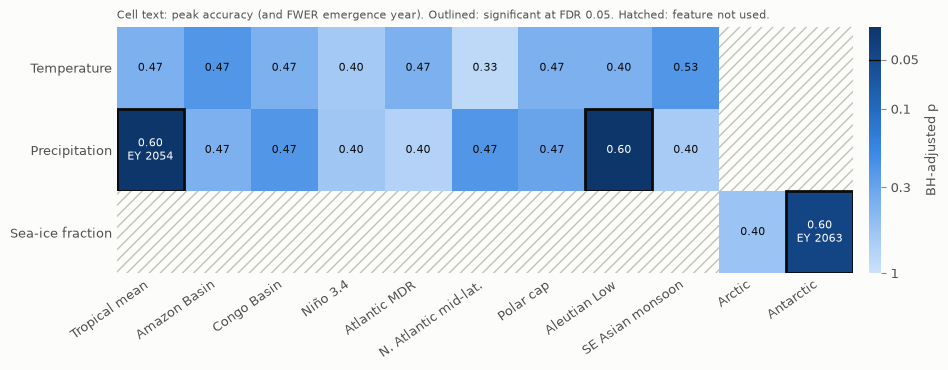

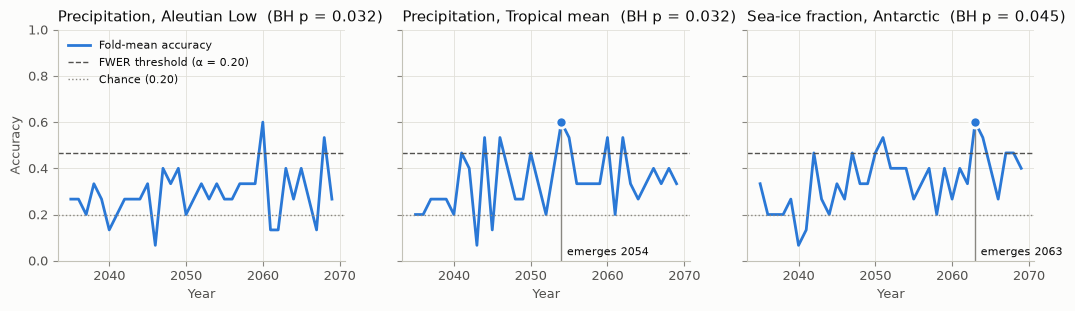

In [40]:
def plot_single_feature_heatmap(emergence_df):
    """Variable x region grid: colour = BH-adjusted p, text = peak accuracy."""
    regions = list(REGIONS) + list(SEAICE_REGIONS)
    grid = emergence_df.set_index(["variable", "region"])
    logp = np.full((len(VARS), len(regions)), np.nan)
    for i, v in enumerate(VARS):
        for j, r in enumerate(regions):
            if (v, r) in grid.index:
                logp[i, j] = -np.log10(grid.loc[(v, r), "p_fdr_bh"])
    vmax = max(1.5, np.nanmax(logp))

    fig, ax = plt.subplots(figsize=(10, 3.2))
    im = ax.imshow(np.ma.masked_invalid(logp), cmap=BLUE_RAMP, vmin=0, vmax=vmax, aspect="auto")
    ax.grid(False)
    for i, v in enumerate(VARS):
        for j, r in enumerate(regions):
            if (v, r) not in grid.index:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=SURFACE,
                                       edgecolor=AXIS, hatch="///", linewidth=0))
                continue
            row = grid.loc[(v, r)]
            text = f"{row['peak_acc']:.2f}"
            if pd.notna(row["fwer_emergence_year"]):
                text += f"\nEY {int(row['fwer_emergence_year'])}"
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="#ffffff" if logp[i, j] > 0.65 * vmax else INK)
            if row["significant_fdr05"]:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=2))

    ax.set_xticks(range(len(regions)), [REGION_NAMES[r] for r in regions], rotation=35, ha="right")
    ax.set_yticks(range(len(VARS)), [VAR_NAMES[v] for v in VARS])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    p_ticks = [p for p in (1, 0.3, 0.1, 0.05, 0.01) if -np.log10(p) <= vmax]
    cb.set_ticks([-np.log10(p) for p in p_ticks], labels=[f"{p:g}" for p in p_ticks])
    cb.set_label("BH-adjusted p")
    cb.ax.axhline(-np.log10(0.05), color=INK, linewidth=1)
    cb.outline.set_visible(False)
    ax.set_title("Cell text: peak accuracy (and FWER emergence year). Outlined: significant at FDR 0.05. "
                "Hatched: feature not used.", loc="left", fontsize=8, color=INK_2)
    save_fig(fig, "fig_single_feature_heatmap")
    return fig


def plot_significant_single_curves(emergence_df, single_curves, chance=1 / len(STRATEGIES)):
    """Accuracy over time for the FDR-significant single-feature models."""
    sig = emergence_df[emergence_df["significant_fdr05"]]
    if sig.empty:
        print("No FDR-significant single region x variable models to plot.")
        return None
    fig, axes = plt.subplots(1, len(sig), figsize=(4.2 * len(sig), 3), sharey=True, squeeze=False)
    for ax, (_, row) in zip(axes[0], sig.iterrows()):
        c = single_curves[f"{row['variable']}_{row['region']}"]
        ax.plot(c["year"], c["mean_acc"], color=SERIES[0], label="Fold-mean accuracy")
        ax.axhline(row["fwer_threshold"], color=INK_2, linestyle="--", linewidth=1,
                   label="FWER threshold (α = 0.20)")
        ax.axhline(chance, color=MUTED, linestyle=":", linewidth=1, label=f"Chance ({chance:.2f})")
        if pd.notna(row["fwer_emergence_year"]):
            mark_emergence(ax, c, int(row["fwer_emergence_year"]))
        ax.set_title(f"{VAR_NAMES[row['variable']]}, {REGION_NAMES[row['region']]}  "
                     f"(BH p = {row['p_fdr_bh']:.3f})", loc="left")
        ax.set_xlabel("Year")
        ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("Accuracy")
    axes[0, 0].legend(loc="upper left", fontsize=8)
    save_fig(fig, "fig_single_feature_significant_curves")
    return fig


plot_single_feature_heatmap(emergence_df);
plot_significant_single_curves(emergence_df, single_curves);

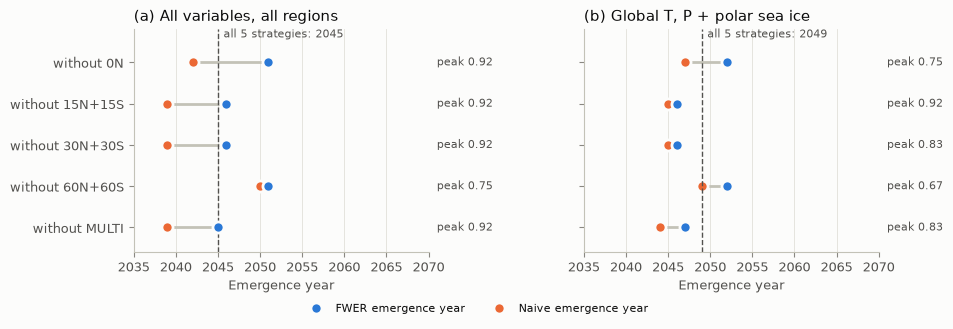

In [41]:
def plot_loso_dumbbell(panels):
    """
    Leave-one-strategy-out analysis presented as a dumbbell plot
    """
    strategies = list(STRATEGIES)[::-1]
    fig, axes = plt.subplots(1, len(panels), figsize=(4.8 * len(panels), 3.1), sharey=True, squeeze=False)
    for ax, (title, d, full_ey) in zip(axes[0], panels):
        d = d.set_index("strategy_left_out")
        for y, s in enumerate(strategies):
            naive, fwer = d.loc[s, "naive_emergence_year"], d.loc[s, "fwer_emergence_year"]
            if pd.notna(naive) and pd.notna(fwer):
                ax.plot([naive, fwer], [y, y], color=AXIS, linewidth=2, zorder=1)
            if pd.notna(naive):
                ax.plot(naive, y, "o", ms=8, color=SERIES[1], mec=SURFACE, mew=2, zorder=2)
            if pd.notna(fwer):
                ax.plot(fwer, y, "o", ms=8, color=SERIES[0], mec=SURFACE, mew=2, zorder=3)
            ax.annotate(f"peak {d.loc[s, 'peak_acc']:.2f}", (1, y), xycoords=("axes fraction", "data"),
                        xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
        if full_ey is not None and pd.notna(full_ey):
            ax.axvline(full_ey, color=INK_2, linestyle="--", linewidth=1)
            ax.annotate(f"all 5 strategies: {int(full_ey)}", (full_ey, len(strategies) - 0.4),
                        xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK_2)
        ax.set_yticks(range(len(strategies)), [f"without {STRATEGY_NAMES[s]}" for s in strategies])
        ax.set_ylim(-0.6, len(strategies) - 0.2)
        ax.set_xlim(YEARS[0], YEARS[-1] + 1)
        ax.set_xlabel("Emergence year")
        ax.grid(axis="y", visible=False)
        ax.set_title(title, loc="left")
    handles = [plt.Line2D([], [], marker="o", ms=8, color=c, mec=SURFACE, mew=2, linestyle="")
               for c in (SERIES[0], SERIES[1])]
    fig.legend(handles, ["FWER emergence year", "Naive emergence year"], loc="lower center",
               ncol=2, bbox_to_anchor=(0.5, -0.06), fontsize=8)
    fig.tight_layout(w_pad=6)
    save_fig(fig, "fig_leave_one_strategy_out")
    return fig;


headline_ey = pd.DataFrame(headline_results).set_index("test")["fwer_emergence_year"]
plot_loso_dumbbell([
    ("(a) All variables, all regions", loso_all_df, headline_ey.get("ALL (regional)")),
    ("(b) Global T, P + polar sea ice", loso_global_df, headline_ey.get("global_only")),
]);

**Probability of MULTI over time: regional features only**

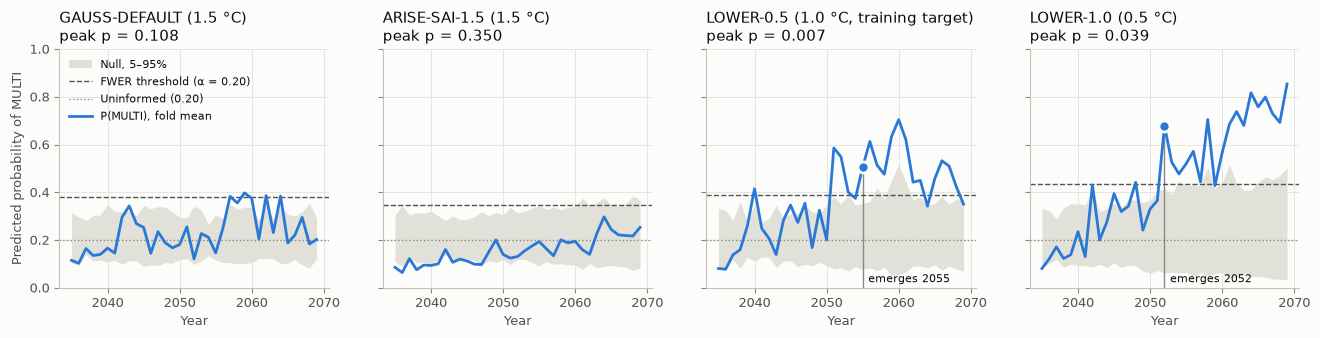

**What the held-out MULTI runs were classified as: regional features only**

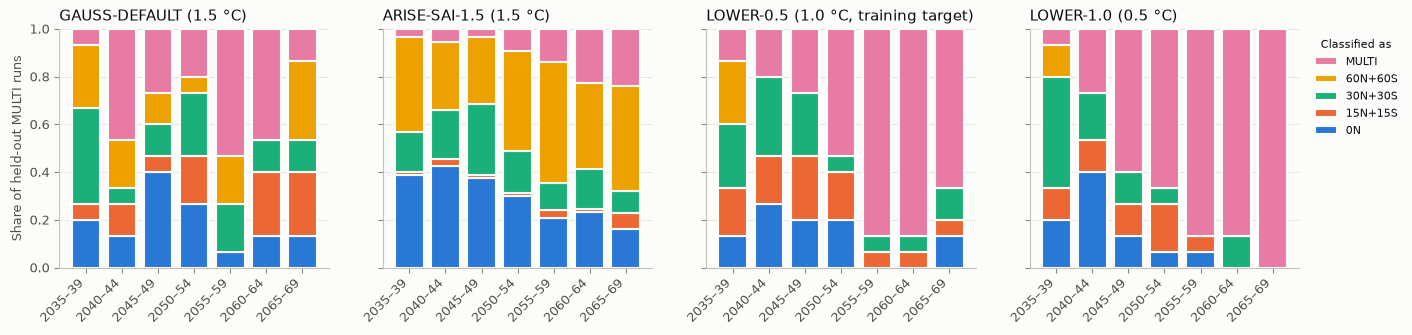

**Probability of MULTI over time: global T, P + polar sea ice**

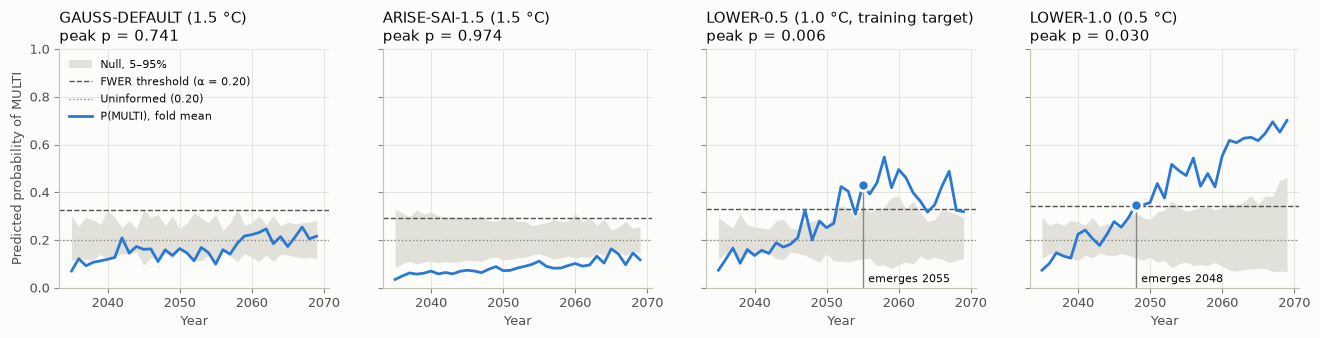

**What the held-out MULTI runs were classified as: global T, P + polar sea ice**

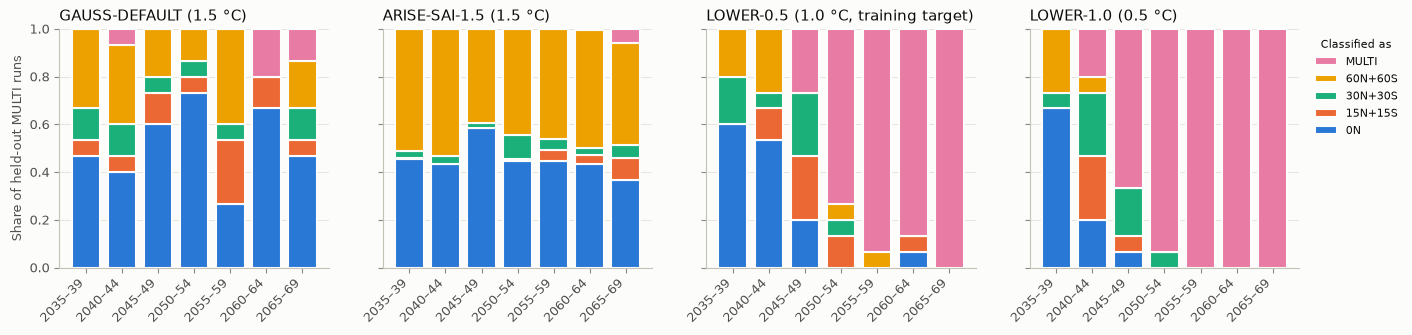

**Probability of MULTI over time: global + regional features**

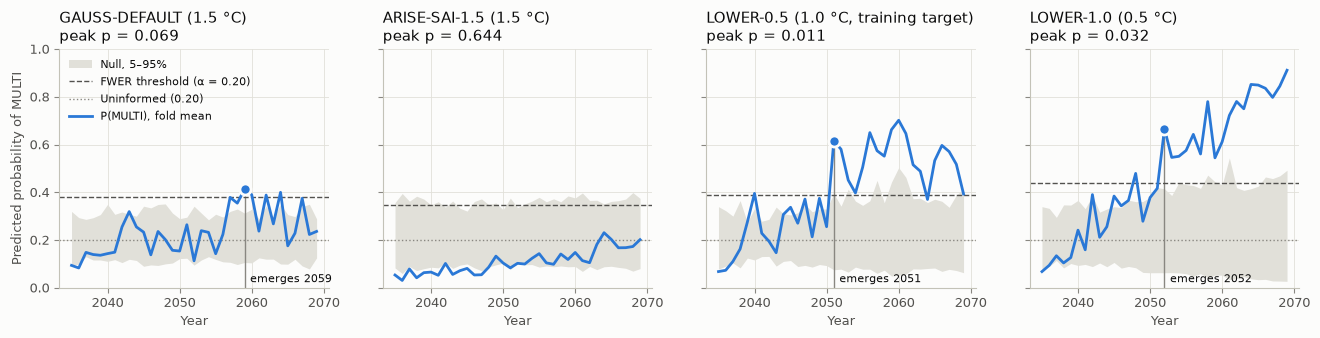

**What the held-out MULTI runs were classified as: global + regional features**

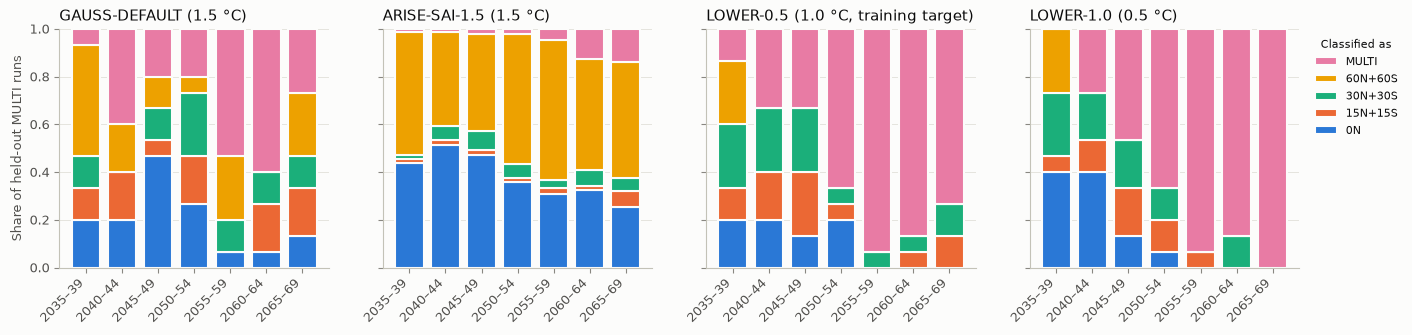

In [42]:
def plot_transfer_curves(transfer_curves, transfer_nulls, transfer_df, chance=1 / len(STRATEGIES), name_suffix=""):
    """Predicted probability of MULTI over time at each target, against its permutation null."""
    res = transfer_df.set_index("test_target")
    order = [t for t in TARGET_ORDER if t in transfer_curves]
    fig, axes = plt.subplots(1, len(order), figsize=(4 * len(order), 3.1), sharey=True, squeeze=False)
    for ax, t in zip(axes[0], order):
        c, r = transfer_curves[t], res.loc[t]
        lo, hi = np.nanpercentile(transfer_nulls[t], [5, 95], axis=0)
        ax.fill_between(c["year"], lo, hi, color=GRID, linewidth=0, label="Null, 5–95%")
        ax.axhline(r["fwer_threshold"], color=INK_2, linestyle="--", linewidth=1,
                   label="FWER threshold (α = 0.20)")
        ax.axhline(chance, color=MUTED, linestyle=":", linewidth=1, label=f"Uninformed ({chance:.2f})")
        ax.plot(c["year"], c["mean_acc"], color=SERIES[0], label="P(MULTI), fold mean")
        if pd.notna(r["fwer_emergence_year"]):
            mark_emergence(ax, c, int(r["fwer_emergence_year"]))
        ax.set_title(f"{TARGET_NAMES[t]}\npeak p = {r['global_fwer_pvalue_of_peak']:.3f}", loc="left")
        ax.set_xlabel("Year")
        ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("Predicted probability of MULTI")
    axes[0, 0].legend(loc="upper left", fontsize=8)
    save_fig(fig, f"fig_cross_target_curves{name_suffix}")
    return fig


def plot_transfer_composition(transfer_preds, period=5, name_suffix=""):
    """What the held-out MULTI runs are classified as, by target and 5-year period."""
    label_to_strategy = {v: k for k, v in STRATEGY_LABELS.items()}
    p = transfer_preds.assign(
        period=(transfer_preds["year"] - YEARS[0]) // period * period + YEARS[0],
        predicted=transfer_preds["pred"].map(label_to_strategy))
    order = [t for t in TARGET_ORDER if t in set(p["target"])]
    fig, axes = plt.subplots(1, len(order), figsize=(4 * len(order), 3.1), sharey=True, squeeze=False)
    for ax, t in zip(axes[0], order):
        share = (p[p["target"] == t].groupby("period")["predicted"].value_counts(normalize=True)
                 .unstack(fill_value=0).reindex(columns=list(STRATEGIES), fill_value=0))
        bottom = np.zeros(len(share))
        for s in STRATEGIES:
            ax.bar(share.index, share[s], bottom=bottom, width=period * 0.8, color=STRATEGY_COLORS[s],
                   edgecolor=SURFACE, linewidth=1.5, label=STRATEGY_NAMES[s])
            bottom += share[s].values
        ax.set_xticks(share.index, [f"{y}–{str(y + period - 1)[-2:]}" for y in share.index],
                      rotation=45, ha="right")
        ax.grid(axis="x", visible=False)
        ax.set_title(TARGET_NAMES[t], loc="left")
        ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("Share of held-out MULTI runs")
    handles, labels = axes[0, -1].get_legend_handles_labels()
    axes[0, -1].legend(handles[::-1], labels[::-1], title="Classified as", loc="upper left",
                       bbox_to_anchor=(1.02, 1), fontsize=8, title_fontsize=8)
    save_fig(fig, f"fig_cross_target_composition{name_suffix}")
    return fig

FEATURE_SET_NAMES = {"regional": "regional features only",
                     "global": "global T, P + polar sea ice",
                     "global_plus_regional": "global + regional features"}

for fs_name, r in transfer_results.items():
    display(Markdown(f"**Probability of MULTI over time: {FEATURE_SET_NAMES[fs_name]}**"))
    plot_transfer_curves(r["curves"], r["nulls"], transfer_df[transfer_df["feature_set"] == fs_name],
                         name_suffix=f"_{fs_name}")
    plt.show()
    display(Markdown(f"**What the held-out MULTI runs were classified as: {FEATURE_SET_NAMES[fs_name]}**"))
    plot_transfer_composition(r["preds"], name_suffix=f"_{fs_name}")
    plt.show()

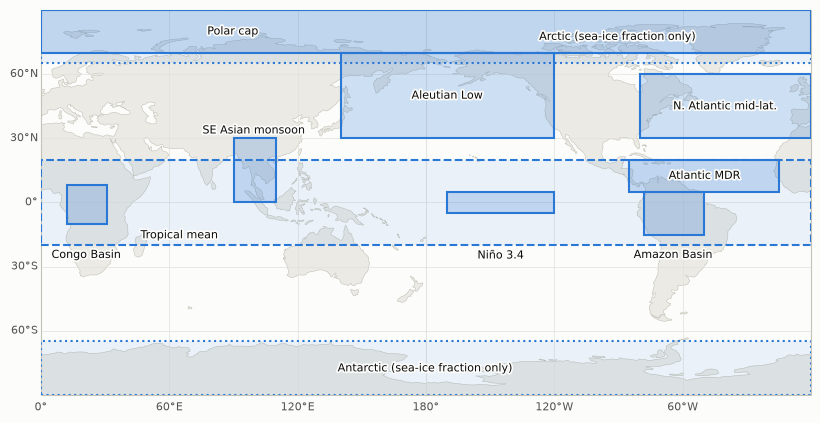

In [43]:
REGION_LABEL_POS = {
    "tropical_mean": (65, -18, "center", "bottom"),
    "amazon_basin": (296, -22, "center", "top"),
    "congo_basin": (21.5, -22, "center", "top"),
    "nino34": (215, -22, "center", "top"),
    "atlantic_mdr": (310, 12.5, "center", "center"),
    "natl_midlat": (320, 45, "center", "center"),
    "polar_cap": (90, 80, "center", "center"),
    "arctic": (270, 77.5, "center", "center"),
    "antarctic": (180, -77.5, "center", "center"),
    "aleutian_low": (190, 50, "center", "center"),
    "se_asia_monsoon": (100, 31, "center", "bottom"),
}

def plot_region_map(region_defs={**REGIONS, **SEAICE_REGIONS}):
    """Map of the region definitions used to generate regional features"""
    data_crs = ccrs.PlateCarree()
    color = SERIES[0]

    fig = plt.figure(figsize=(10, 5))
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
    ax.set_extent([0, 359.9, -90, 90], crs=data_crs)
    ax.add_feature(cfeature.LAND, facecolor="#ebeae5", edgecolor="none", zorder=0)
    ax.add_feature(cfeature.COASTLINE, edgecolor=AXIS, linewidth=0.4, zorder=1)
    gl = ax.gridlines(draw_labels=True, color=GRID, linewidth=0.5, xlocs=range(-180, 181, 60),
                      ylocs=range(-90, 91, 30))
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"color": INK_2, "size": 8}

    for name, d in region_defs.items():
        (lat0, lat1), (lon0, lon1) = d["lat"], d["lon"]
        is_band = name == "tropical_mean"
        is_seaice = name in SEAICE_REGIONS
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, transform=data_crs,
                               facecolor=color, alpha=0.08 if (is_band or is_seaice) else 0.22, edgecolor="none",
                               zorder=2))
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, transform=data_crs,
                               fill=False, edgecolor=color, linewidth=1.5,
                               linestyle=":" if is_seaice else ("--" if is_band else "-"), zorder=3))
        lon, lat, ha, va = REGION_LABEL_POS[name]
        label = f"{REGION_NAMES[name]} (sea-ice fraction only)" if is_seaice else REGION_NAMES[name]
        ax.text(lon, lat, label, transform=data_crs, ha=ha, va=va, fontsize=8,
                color=INK, zorder=4, path_effects=[pe.withStroke(linewidth=2.5, foreground=SURFACE)])
        
    save_fig(fig, "fig_region_map")
    return fig

plot_region_map();